In [18]:
#Commands to access the datasets on Kaggle
#Make a seperate directory for kaggle and give access for Kaggle to export datasets
! mkdir ~/.kaggle
! cp kaggle.json ~/.kaggle/
! chmod 600 ~/.kaggle/kaggle.json

mkdir: cannot create directory ‘/root/.kaggle’: File exists
cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory


In [19]:
#Download the dataset
!kaggle datasets download -d uraninjo/augmented-alzheimer-mri-dataset

Dataset URL: https://www.kaggle.com/datasets/uraninjo/augmented-alzheimer-mri-dataset
License(s): GNU Lesser General Public License 3.0
augmented-alzheimer-mri-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)


The datasets consists only images, which are divided into four categories, namely:
1. Very MildDemented
2. Mild Demented
3. Moderate Demented
4. Non-Demented

The dataset is currently downloaded in a zipfile format. Unzip the folder to access the data.

In [20]:
#Unzipping the zipfile of images
import zipfile

data_zip = zipfile.ZipFile('/content/augmented-alzheimer-mri-dataset.zip')
data_zip.extractall()
data_zip.close()

There are two folders in the datasets- One with original images and the other with augmented images.

Seperate them by assigning them as testing and training, respectively.

In [21]:
!kaggle datasets download -d pranavraikokte/covid19-image-dataset

Dataset URL: https://www.kaggle.com/datasets/pranavraikokte/covid19-image-dataset
License(s): CC-BY-SA-4.0
covid19-image-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)


In [22]:
#Unzipping the zipfile of images
import zipfile

data_zip = zipfile.ZipFile('/content/covid19-image-dataset.zip')
data_zip.extractall()
data_zip.close()

In [23]:
#Create seperate directories for training and testing images.

train_dir = '/content/AugmentedAlzheimerDataset/'
test_dir = '/content/OriginalDataset'

In [24]:
#Import all the required libraries for data pre-processing and training.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers

The images are further partitioned into training and validation images with 80% training and 20% validation.

In [25]:
#Create instances of ImageDataGenerator by setting a rescale value and validation split.

train_datagen = ImageDataGenerator(rescale = 1/255. , validation_split = 0.2)
test_datagen = ImageDataGenerator(rescale = 1/255.)

In [26]:
train_data = train_datagen.flow_from_directory(train_dir ,
                                               target_size = (224 , 224),    #Set image size.
                                               batch_size = 32,              #Set appropriate batch size to avoid overfitting.
                                               class_mode = 'categorical',   #Set type of labels.
                                               subset = 'training')

valid_data = train_datagen.flow_from_directory(train_dir,
                                               target_size = (224 , 224),
                                               batch_size = 32,
                                               class_mode = 'categorical',
                                               subset = 'validation')

test_data = test_datagen.flow_from_directory(test_dir,
                                             target_size = (224 , 224),         #Images from the OriginalDataset directory to be used for testing only
                                             batch_size = 32,
                                             class_mode = 'categorical')

Found 27188 images belonging to 4 classes.
Found 6796 images belonging to 4 classes.
Found 6400 images belonging to 4 classes.


In [27]:
#Define a function to plot the loss and accuracy curves of model training for better visualization.

def loss_and_accuracy(history):

  loss = history.history['loss']
  val_loss = history.history['val_loss']

  accuracy = history.history['accuracy']
  val_accuracy = history.history['val_accuracy']

  epochs = range(len(history.history['loss']))

  plt.plot(epochs , loss , label = 'Training Loss')
  plt.plot(epochs , val_loss , label = 'Validation Loss')            #Loss curve
  plt.title('Loss Curve')
  plt.xlabel('epochs')
  plt.legend()
  plt.savefig('Loss_Curve.jpg')

  plt.figure()

  plt.plot(epochs , accuracy , label = 'training_accuracy')
  plt.plot(epochs , val_accuracy , label = 'validation_accuracy')    #Accuracy curve
  plt.title('Accuracy Curve')
  plt.yticks([0,0.2,0.4,0.6,0.8,1])
  plt.xlabel('epochs')
  plt.legend()
  plt.savefig('Accuracy_Curve.jpg')

In [28]:
#Give the classnames as a list
classnames = ['Mild Demented' , 'Moderate Demented' , 'Non-Demented' , 'Very Mild Demented']

In [29]:
#Define a function to prepare an image for prediction

def image_prep(filename , img_size = 224):
  #Read the image from filename
  image = tf.io.read_file(filename)
  #Decode the image into its RGB channels
  image = tf.image.decode_image(image , channels = 3)
  #Resize the image
  image = tf.image.resize(image , size = [img_size , img_size])
  #Rescale
  image = image/255.

  return image

In [30]:
#Define a function to make predictions on the prepared images
#Image along with the classified label is shown as output

def make_predictions(model , filename , classnames):
  #Load the image
  image = image_prep(filename)
  #Run the model on the image
  pred = model.predict(tf.expand_dims(image , axis=0))
  #Zero down on the class
  pred_class = classnames[tf.argmax(tf.round(pred)[0])]
  #Show the image and the label
  plt.imshow(image)
  plt.title(f'Predicted class: {pred_class}')
  plt.axis(False)

In [31]:
import os

# Create a directory to save model artifacts
if not os.path.exists('model_artifacts'):
    os.makedirs('model_artifacts')

# Create an EarlyStopping callback method that stops training when accuracy does not improve.
# Monitor validation loss to restore best weights
callback_early_stopping = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

# Reduce learning rate when a metric has stopped improving.
callback_reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=5, min_lr=0.00001)

# Save the best model based on validation loss
callback_model_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath='model_artifacts/best_model.keras',
    monitor='val_loss',
    save_best_only=True,
    verbose=1
)

callbacks_list = [callback_early_stopping, callback_reduce_lr, callback_model_checkpoint]

In [32]:
model_1 = tf.keras.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(224, 224, 3)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.GlobalAveragePooling2D(), # Use GlobalAveragePooling2D instead of Flatten
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(len(classnames), activation='softmax') # Output layer for 4 classes
])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [33]:
model_1.compile(loss = 'categorical_crossentropy',
                optimizer = tf.keras.optimizers.Adam(),
                metrics = ['accuracy'])

In [34]:
# Measure training time
import time
start_time = time.time()

history_1 = model_1.fit(train_data,
                        epochs = 50, # Set a higher number of epochs, EarlyStopping will manage it
                        validation_data = valid_data,
                        callbacks = callbacks_list, # Use the defined callbacks list
                        verbose = 1) # Set verbose to 1 to see training progress

end_time = time.time()
training_time = end_time - start_time
print(f"\nTraining completed in {training_time:.2f} seconds")

Epoch 1/50
850/850 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.3706 - loss: 1.5112
Epoch 1: val_loss improved from None to 7.75380, saving model to model_artifacts/best_model.keras

Epoch 1: finished saving model to model_artifacts/best_model.keras
850/850 ━━━━━━━━━━━━━━━━━━━━ 87s 87ms/step - accuracy: 0.4243 - loss: 1.3204 - val_accuracy: 0.2830 - val_loss: 7.7538 - learning_rate: 0.0010
Epoch 2/50
850/850 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.5394 - loss: 1.0103
Epoch 2: val_loss improved from 7.75380 to 3.44994, saving model to model_artifacts/best_model.keras

Epoch 2: finished saving model to model_artifacts/best_model.keras
850/850 ━━━━━━━━━━━━━━━━━━━━ 67s 79ms/step - accuracy: 0.5593 - loss: 0.9580 - val_accuracy: 0.2952 - val_loss: 3.4499 - learning_rate: 0.0010
Epoch 3/50
850/850 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.6177 - loss: 0.8335
Epoch 3: val_loss improved from 3.44994 to 2.13091, saving model to model_artifacts/best_model.keras

Epoch 3: finishe

In [39]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc, RocCurveDisplay
import seaborn as sns
import pickle

# --- 1. Extract Training and Validation Metrics ---

train_accuracy = history_1.history['accuracy'][-1]
val_accuracy = history_1.history['val_accuracy'][-1]
train_loss = history_1.history['loss'][-1]
val_loss = history_1.history['val_loss'][-1]

# --- 2. Evaluate Model on Test Data ---
print("\nEvaluating model on test data...")
test_loss, test_accuracy = model_1.evaluate(test_data, verbose=0)

print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Validation Accuracy: {val_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Training Loss: {train_loss:.4f}")
print(f"Validation Loss: {val_loss:.4f}")
print(f"Test Loss: {test_loss:.4f}")


Evaluating model on test data...
Training Accuracy: 0.9240
Validation Accuracy: 0.9576
Test Accuracy: 0.9373
Training Loss: 0.2005
Validation Loss: 0.1277
Test Loss: 0.1627


### Accuracy and Loss Plots

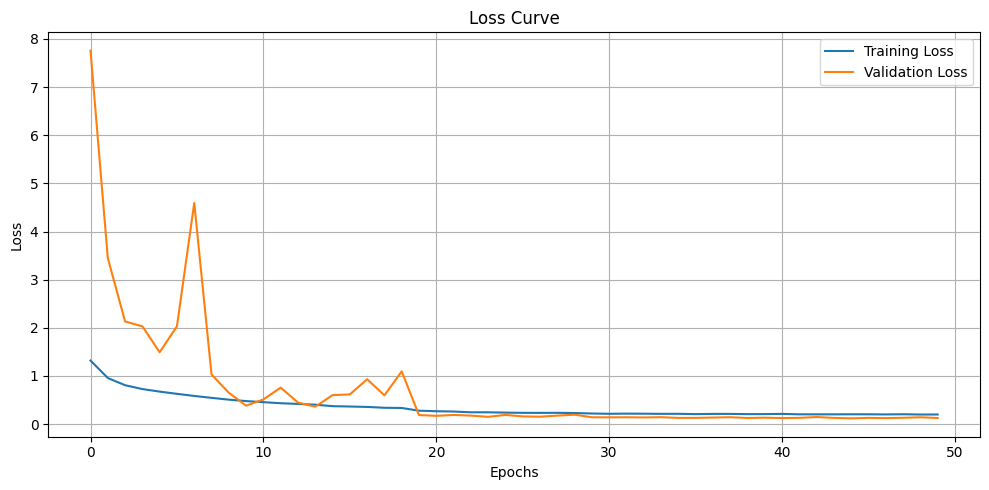

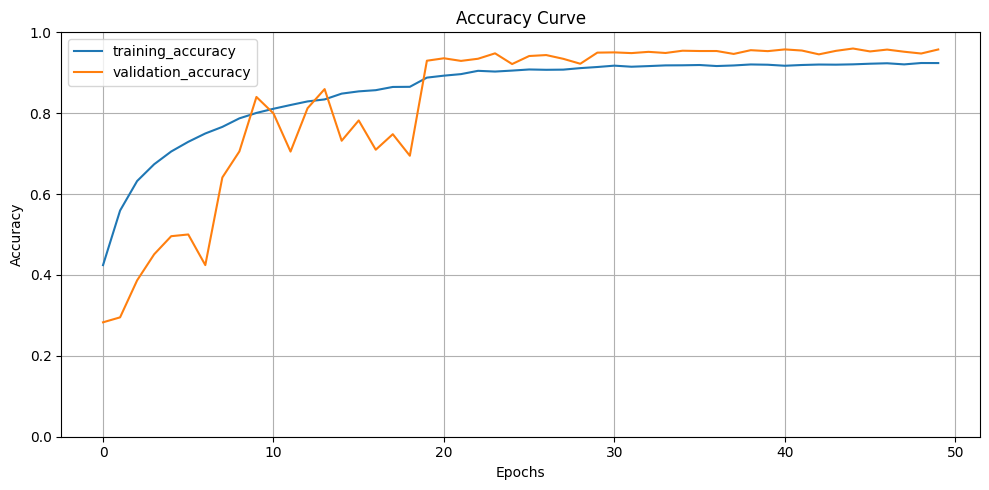

In [40]:
# Modify the existing loss_and_accuracy function to save as PNG and display plots
# Note: This cell is intentionally placed here to ensure the modified function is used
# for plotting based on the history_1 object from the previous training step.

def loss_and_accuracy(history, accuracy_plot_filename='accuracy_curve.png', loss_plot_filename='loss_curve.png'):

  loss = history.history['loss']
  val_loss = history.history['val_loss']

  accuracy = history.history['accuracy']
  val_accuracy = history.history['val_accuracy']

  epochs = range(len(history.history['loss']))

  plt.figure(figsize=(10, 5)) # Added for better plot sizing
  plt.plot(epochs , loss , label = 'Training Loss')
  plt.plot(epochs , val_loss , label = 'Validation Loss')            #Loss curve
  plt.title('Loss Curve')
  plt.xlabel('Epochs') # Changed to 'Epochs'
  plt.ylabel('Loss') # Added y-label
  plt.legend()
  plt.grid(True) # Added grid
  plt.tight_layout() # Adjust layout
  plt.savefig(f'model_artifacts/{loss_plot_filename}') # Save as PNG in artifacts directory

  plt.figure(figsize=(10, 5)) # Added for better plot sizing
  plt.plot(epochs , accuracy , label = 'training_accuracy')
  plt.plot(epochs , val_accuracy , label = 'validation_accuracy')    #Accuracy curve
  plt.title('Accuracy Curve')
  plt.yticks([0,0.2,0.4,0.6,0.8,1])
  plt.xlabel('Epochs') # Changed to 'Epochs'
  plt.ylabel('Accuracy') # Added y-label
  plt.legend()
  plt.grid(True) # Added grid
  plt.tight_layout() # Adjust layout
  plt.savefig(f'model_artifacts/{accuracy_plot_filename}') # Save as PNG in artifacts directory

  plt.show() # Display plots


loss_and_accuracy(history_1, accuracy_plot_filename='accuracy_curve.png', loss_plot_filename='loss_curve.png')

### Classification Report and Confusion Matrix

200/200 ━━━━━━━━━━━━━━━━━━━━ 8s 35ms/step

Classification Report:
                    precision    recall  f1-score   support

     Mild Demented       0.14      0.12      0.13       896
 Moderate Demented       0.00      0.00      0.00        64
      Non-Demented       0.50      0.51      0.50      3200
Very Mild Demented       0.35      0.35      0.35      2240

          accuracy                           0.40      6400
         macro avg       0.25      0.25      0.25      6400
      weighted avg       0.39      0.40      0.39      6400



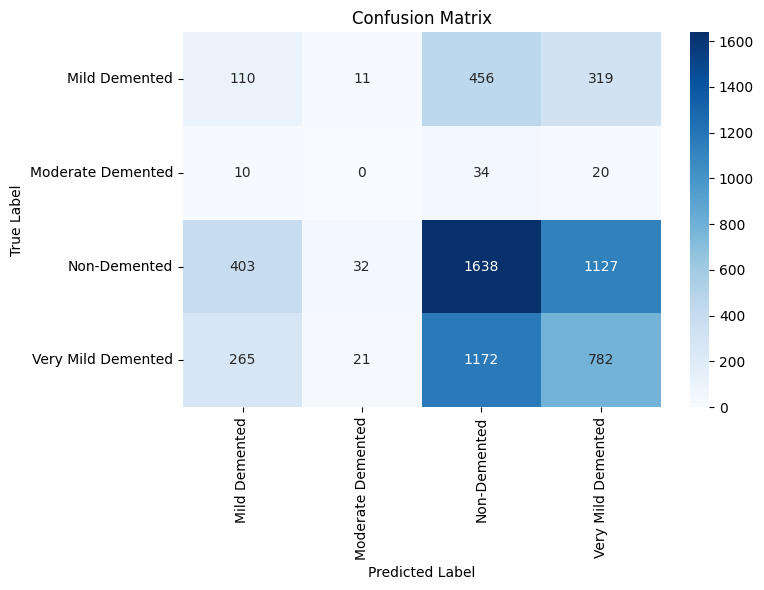


Per-class Accuracy:
  Mild Demented: 0.1228
  Moderate Demented: 0.0000
  Non-Demented: 0.5119
  Very Mild Demented: 0.3491


In [41]:
# --- 3. Generate predictions and True Labels ---

# Reset test_data to ensure predictions are in order
test_data.reset()

# Get true labels
y_true = test_data.classes

# Get predictions (probabilities)
# Predict on the entire test dataset
y_pred_probs = model_1.predict(test_data, verbose=1)

# Convert probabilities to predicted class labels
y_pred_labels = np.argmax(y_pred_probs, axis=1)

# --- 4. Confusion Matrix and Classification Report ---

print("\nClassification Report:")
print(classification_report(y_true, y_pred_labels, target_names=classnames))

cm = confusion_matrix(y_true, y_pred_labels)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classnames, yticklabels=classnames)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.savefig('model_artifacts/confusion_matrix.png')
plt.show()

# --- 5. Per-class Accuracy ---
print("\nPer-class Accuracy:")
for i, class_name in enumerate(classnames):
    true_positives = cm[i, i]
    total_actual = np.sum(cm[i, :])
    class_accuracy = true_positives / total_actual if total_actual > 0 else 0
    print(f"  {class_name}: {class_accuracy:.4f}")

### ROC Curve and AUC Score (One-vs-Rest)

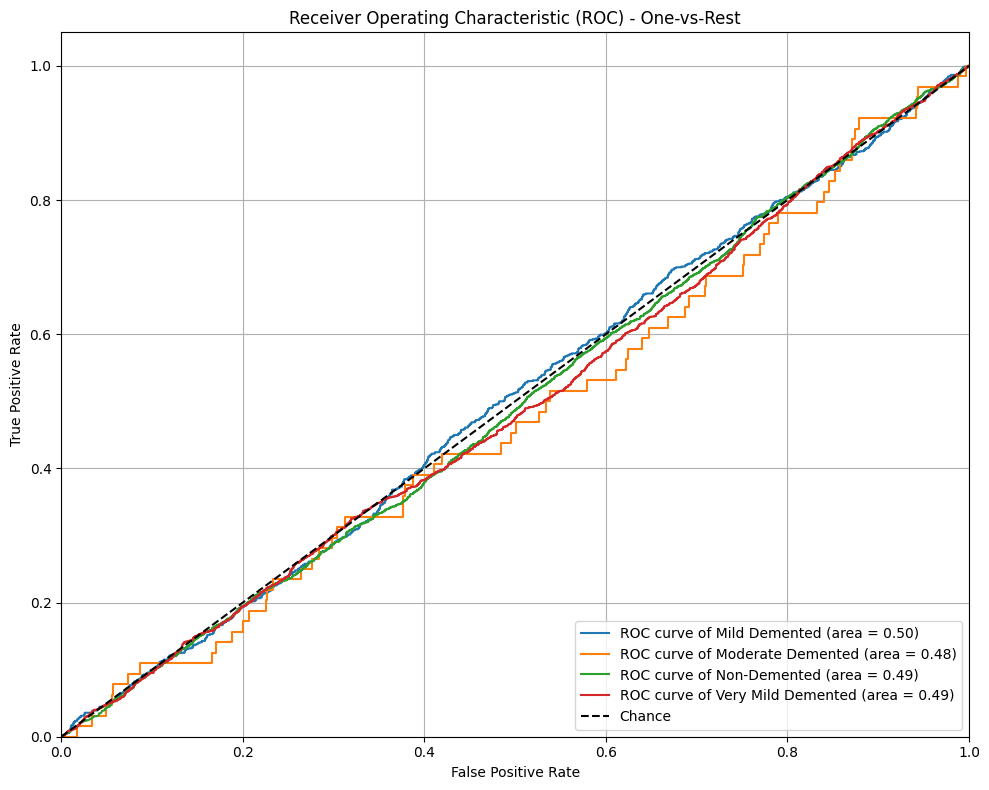


Macro AUC Score: 0.4902


In [42]:
# --- 6. ROC Curve and AUC Score ---

plt.figure(figsize=(10, 8))
all_fpr = []
all_tpr = []
all_auc = []

for i, class_name in enumerate(classnames):
    fpr, tpr, _ = roc_curve(y_true == i, y_pred_probs[:, i])
    roc_auc = auc(fpr, tpr)
    all_fpr.append(fpr)
    all_tpr.append(tpr)
    all_auc.append(roc_auc)
    plt.plot(fpr, tpr, label=f'ROC curve of {class_name} (area = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], 'k--', label='Chance')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) - One-vs-Rest')
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.savefig('model_artifacts/roc_curve.png')
plt.show()

macro_auc_score = np.mean(all_auc)
print(f"\nMacro AUC Score: {macro_auc_score:.4f}")

### Random Predictions with Confidence

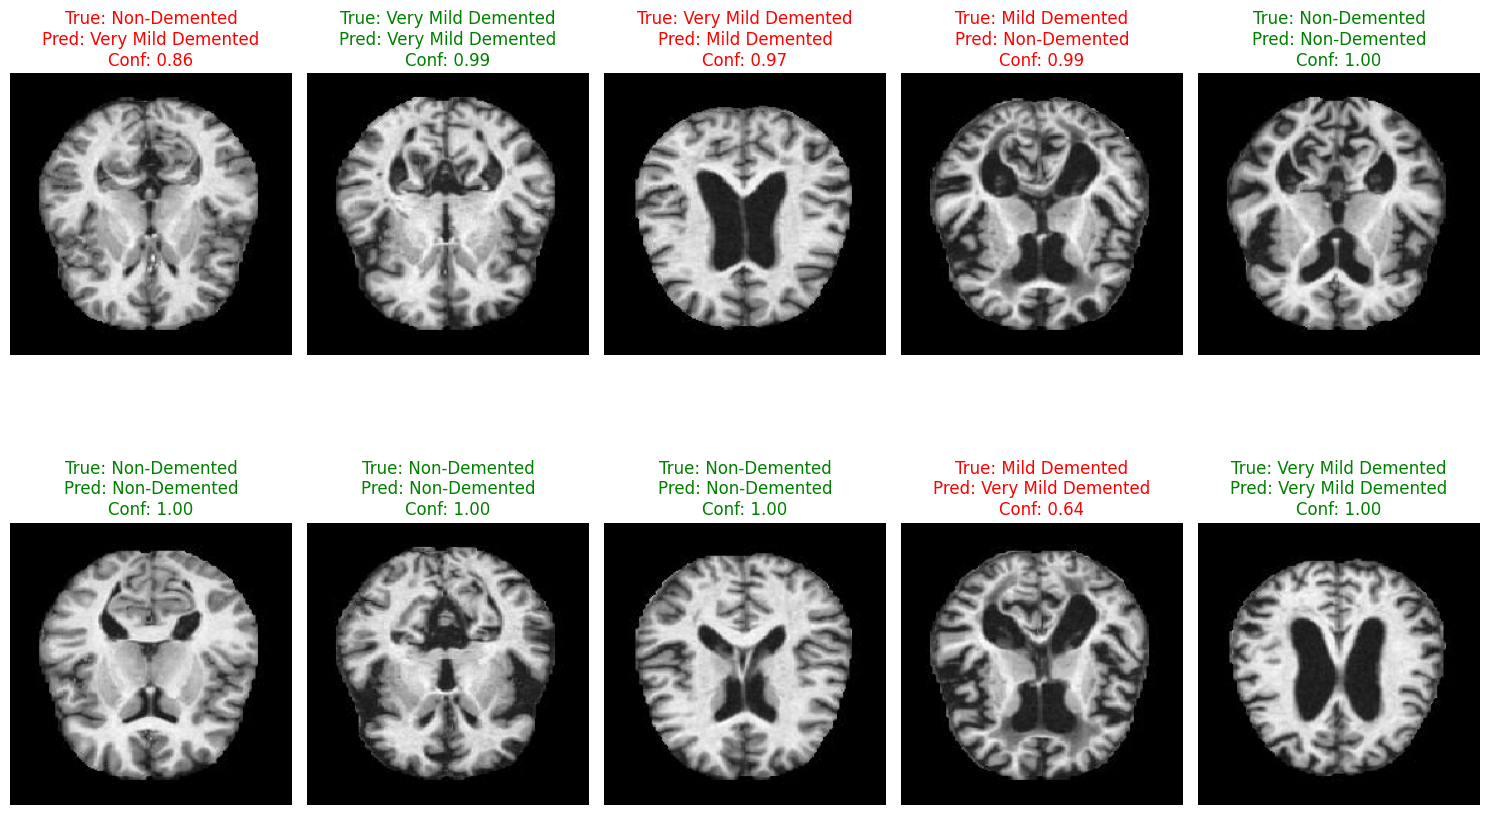


--- Random Correctly Classified Images ---


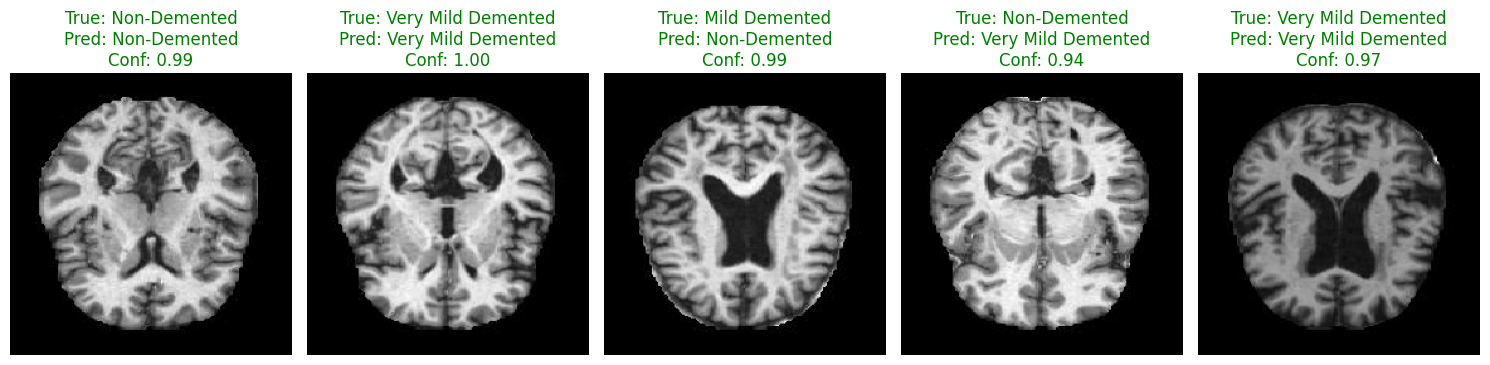


--- Random Misclassified Images ---


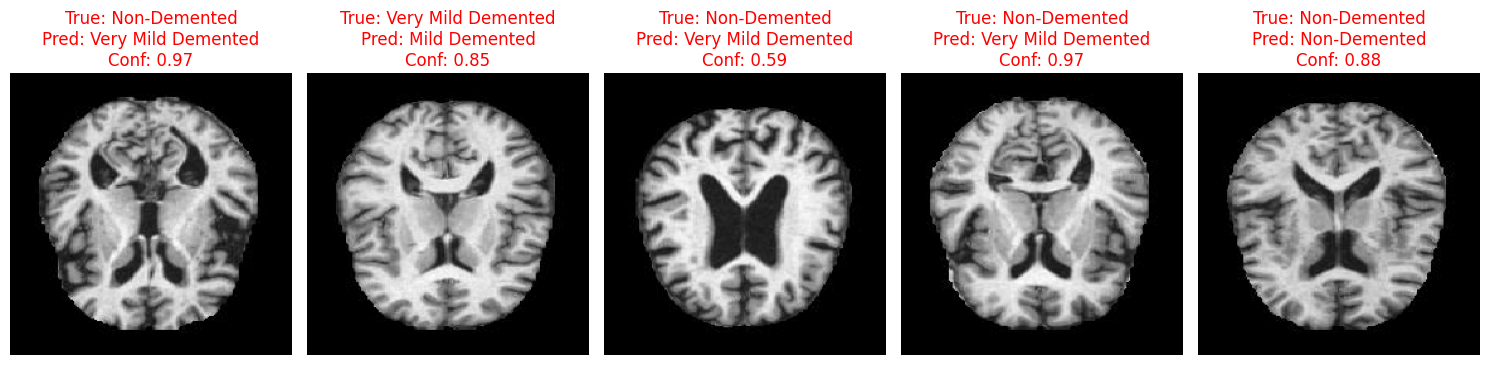

In [43]:
# --- 7. Display Random Predictions ---

def get_image_paths_and_labels(data_generator):
    # Get all image file paths and their corresponding class indices
    fpaths = [data_generator.filepaths[i] for i in data_generator.index_array]
    labels = [data_generator.classes[i] for i in data_generator.index_array]
    return fpaths, labels

image_fpaths, true_labels = get_image_paths_and_labels(test_data)

num_samples_to_display = 10

# Randomly select indices for display
random_indices = np.random.choice(len(image_fpaths), num_samples_to_display, replace=False)

plt.figure(figsize=(15, 10))
for i, idx in enumerate(random_indices):
    img_path = image_fpaths[idx]
    true_label_idx = true_labels[idx]
    predicted_probs = y_pred_probs[idx]
    predicted_label_idx = y_pred_labels[idx]
    confidence = predicted_probs[predicted_label_idx]

    # Load and display image
    img = tf.keras.preprocessing.image.load_img(img_path, target_size=(224, 224))
    plt.subplot(2, 5, i + 1)
    plt.imshow(img)
    plt.title(f"True: {classnames[true_label_idx]}\nPred: {classnames[predicted_label_idx]}\nConf: {confidence:.2f}",
              color='green' if true_label_idx == predicted_label_idx else 'red')
    plt.axis('off')
plt.tight_layout()
plt.show()

# --- Optional: Display random correctly and misclassified images ---
correct_indices = np.where(y_true == y_pred_labels)[0]
misclassified_indices = np.where(y_true != y_pred_labels)[0]

print("\n--- Random Correctly Classified Images ---")
plt.figure(figsize=(15, 5))
for i in range(min(5, len(correct_indices))):
    idx = np.random.choice(correct_indices)
    img_path = image_fpaths[idx]
    true_label_idx = true_labels[idx]
    predicted_probs = y_pred_probs[idx]
    predicted_label_idx = y_pred_labels[idx]
    confidence = predicted_probs[predicted_label_idx]

    img = tf.keras.preprocessing.image.load_img(img_path, target_size=(224, 224))
    plt.subplot(1, 5, i + 1)
    plt.imshow(img)
    plt.title(f"True: {classnames[true_label_idx]}\nPred: {classnames[predicted_label_idx]}\nConf: {confidence:.2f}", color='green')
    plt.axis('off')
plt.tight_layout()
plt.show()

print("\n--- Random Misclassified Images ---")
plt.figure(figsize=(15, 5))
for i in range(min(5, len(misclassified_indices))):
    idx = np.random.choice(misclassified_indices)
    img_path = image_fpaths[idx]
    true_label_idx = true_labels[idx]
    predicted_probs = y_pred_probs[idx]
    predicted_label_idx = y_pred_labels[idx]
    confidence = predicted_probs[predicted_label_idx]

    img = tf.keras.preprocessing.image.load_img(img_path, target_size=(224, 224))
    plt.subplot(1, 5, i + 1)
    plt.imshow(img)
    plt.title(f"True: {classnames[true_label_idx]}\nPred: {classnames[predicted_label_idx]}\nConf: {confidence:.2f}", color='red')
    plt.axis('off')
plt.tight_layout()
plt.show()

### Final Summary

In [44]:
# --- 8. Save Training History ---
with open('model_artifacts/training_history.pkl', 'wb') as f:
    pickle.dump(history_1.history, f)

# --- 9. Print Final Summary ---

# Recalculate precision, recall, f1 for the summary in case report details differ
report = classification_report(y_true, y_pred_labels, target_names=classnames, output_dict=True)

macro_precision = report['macro avg']['precision']
macro_recall = report['macro avg']['recall']
macro_f1 = report['macro avg']['f1-score']

weighted_precision = report['weighted avg']['precision']
weighted_recall = report['weighted avg']['recall']
weighted_f1 = report['weighted avg']['f1-score']

# Get total parameters
total_parameters = model_1.count_params()

print("\nDataset:")
print(f"Training Samples: {train_data.samples}")
print(f"Validation Samples: {valid_data.samples}")
print(f"Number of Classes: {len(classnames)}")

print("\nTraining Accuracy:", f"{train_accuracy:.4f}")
print("Validation Accuracy:", f"{val_accuracy:.4f}")
print("Test Accuracy:", f"{test_accuracy:.4f}")

print("\nPrecision:")
print(f"  Macro Precision: {macro_precision:.4f}")
print(f"  Weighted Precision: {weighted_precision:.4f}")

print("Recall:")
print(f"  Macro Recall: {macro_recall:.4f}")
print(f"  Weighted Recall: {weighted_recall:.4f}")

print("F1 Score:")
print(f"  Macro F1 Score: {macro_f1:.4f}")
print(f"  Weighted F1 Score: {weighted_f1:.4f}")

print("ROC-AUC:", f"{macro_auc_score:.4f}")

print("\nTotal Parameters:", total_parameters)
print("Training Time:", f"{training_time:.2f} seconds")


Dataset:
Training Samples: 27188
Validation Samples: 6796
Number of Classes: 4

Training Accuracy: 0.9240
Validation Accuracy: 0.9576
Test Accuracy: 0.9373

Precision:
  Macro Precision: 0.2460
  Weighted Precision: 0.3895
Recall:
  Macro Recall: 0.2459
  Weighted Recall: 0.3953
F1 Score:
  Macro F1 Score: 0.2458
  Weighted F1 Score: 0.3923
ROC-AUC: 0.4902

Total Parameters: 129220
Training Time: 3320.65 seconds


In [35]:
len(history_1.history['loss'])

50

In [36]:
model_1.evaluate(train_data)

850/850 ━━━━━━━━━━━━━━━━━━━━ 38s 45ms/step - accuracy: 0.9834 - loss: 0.0605
850/850 ━━━━━━━━━━━━━━━━━━━━ 38s 45ms/step - accuracy: 0.9834 - loss: 0.0605


[0.060499537736177444, 0.9834485650062561]

[0.060499537736177444, 0.9834485650062561]

In [ ]:
loss_and_accuracy(history = history_1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 865ms/step


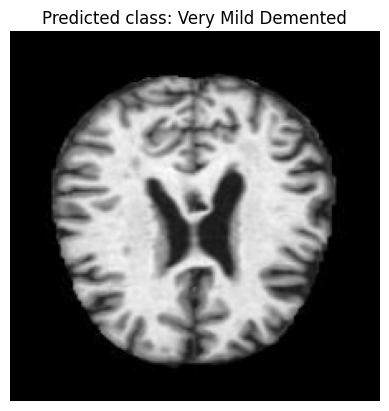

In [ ]:
make_predictions(model_1 , '/content/OriginalDataset/VeryMildDemented/26 (45).jpg' , classnames )